# 04 Fatality Weight Sensitivity

This is the **first sensitivity experiment**. It varies only the fatality exponent in the verified reconstructed DFSI while keeping every other component and transformation unchanged. The comparison baseline is the correctly reconstructed exponent-2 DFSI from `data/processed/dfsi_verified_baseline.csv`, not the published DFSI.

## Setup

In [1]:
from pathlib import Path
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 160)
pd.set_option("display.max_colwidth", 160)

EXPECTED_BASELINE = Path("data") / "processed" / "dfsi_verified_baseline.csv"


def find_project_root(start_path):
    start_path = Path(start_path).resolve()
    for candidate in [start_path, *start_path.parents]:
        if (candidate / EXPECTED_BASELINE).exists():
            return candidate
    raise FileNotFoundError("Could not find data/processed/dfsi_verified_baseline.csv from the current working directory.")


PROJECT_ROOT = find_project_root(Path.cwd())
BASELINE_PATH = PROJECT_ROOT / EXPECTED_BASELINE
TABLE_DIR = PROJECT_ROOT / "outputs" / "tables"
FIGURE_DIR = PROJECT_ROOT / "outputs" / "figures"
TABLE_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

FATALITY_EXPONENTS = [1.0, 1.5, 2.0, 2.5, 3.0]
BASELINE_EXPONENT = 2.0

print(f"Project root: {PROJECT_ROOT}")
print(f"Baseline input: {BASELINE_PATH.relative_to(PROJECT_ROOT)}")

Project root: /Users/abhijithshaji/Documents/india-flood-index-robustness
Baseline input: data/processed/dfsi_verified_baseline.csv


## Load Complete Valid Verified Baseline Records

Only `data/processed/dfsi_verified_baseline.csv` is used. Incomplete rows are excluded from this sensitivity experiment; no missing components are imputed.

In [2]:
baseline = pd.read_csv(BASELINE_PATH)
print(f"Verified baseline rows: {len(baseline):,}")
print("Columns:")
print(list(baseline.columns))

required_columns = [
    "State_Name",
    "district_name",
    "available_state_identifier",
    "available_state_review_key",
    "available_district_identifier",
    "available_district_review_key",
    "available_district_lgd_codes",
    "available_district_lgd_code_count",
    "flood_event_count",
    "mean_flood_duration",
    "fatalities",
    "injured",
    "corrected_percent_flooded_area",
    "population",
    "reconstructed_dfsi",
    "completeness_status",
    "join_status",
]
missing_columns = [column for column in required_columns if column not in baseline.columns]
if missing_columns:
    raise KeyError(f"Missing required verified-baseline columns: {missing_columns}")

complete = baseline.query("completeness_status == 'complete' and join_status == 'one_to_one_comparison_record'").copy()
component_columns = ["flood_event_count", "mean_flood_duration", "fatalities", "injured", "corrected_percent_flooded_area", "population"]
for column in component_columns:
    complete[column] = pd.to_numeric(complete[column], errors="coerce").astype("float64")
complete = complete.dropna(subset=component_columns).copy()

for column in component_columns:
    assert complete[column].ge(0).all(), f"Negative component found in {column}"
assert complete["population"].gt(0).all(), "Population must be positive"

print(f"Complete valid sensitivity records: {len(complete):,}")
display(complete.head())

Verified baseline rows: 720
Columns:
['State_Name', 'district_name', 'available_state_identifier', 'available_state_review_key', 'available_district_identifier', 'available_district_review_key', 'available_district_lgd_codes', 'available_district_lgd_code_count', 'inventory_district_names', 'dfsi_source_row_id', 'impact_source_row_id', 'area_source_row_id', 'flood_event_count', 'mean_flood_duration', 'fatalities', 'injured', 'corrected_percent_flooded_area', 'population', 'published_dfsi', 'reconstructed_dfsi', 'reconstructed_dfsi_product_space', 'log_product_agreement_abs_diff', 'published_rank', 'reconstructed_rank', 'numerical_difference', 'absolute_difference', 'rank_difference', 'absolute_rank_difference', 'completeness_status', 'join_status']
Complete valid sensitivity records: 709


,State_Name,district_name,available_state_identifier,available_state_review_key,available_district_identifier,available_district_review_key,available_district_lgd_codes,available_district_lgd_code_count,inventory_district_names,dfsi_source_row_id,impact_source_row_id,area_source_row_id,flood_event_count,mean_flood_duration,fatalities,injured,corrected_percent_flooded_area,population,published_dfsi,reconstructed_dfsi,reconstructed_dfsi_product_space,log_product_agreement_abs_diff,published_rank,reconstructed_rank,numerical_difference,absolute_difference,rank_difference,absolute_rank_difference,completeness_status,join_status
0,DADRA & NAGAR HAVE,Dadra & Nagar Haveli,DADRA & NAGAR HAVE,dadra & nagar have,Dadra & Nagar Haveli,dadra & nagar haveli,NaN,0,NaN,653,0,0,0.0,1.0,10.0,0.0,2.969168,618459.0,9.820211,8.773826,8.773826,0.0,630.0,637.0,-1.046385,1.046385,7.0,7.0,complete,one_to_one_comparison_record
3,ANDAMAN & NICOBAR,North & Middle Andaman,ANDAMAN & NICOBAR,andaman & nicobar,North & Middle Andaman,north & middle andaman,NaN,0,NaN,726,3,3,0.0,1.0,0.0,0.0,1.314817,101677.0,7.462575,5.672769,5.672769,0.0,703.0,709.0,-1.789805,1.789805,6.0,6.0,complete,one_to_one_comparison_record
4,ANDAMAN & NICOBAR,South Andaman,ANDAMAN & NICOBAR,andaman & nicobar,South Andaman,south andaman,NaN,0,NaN,703,4,4,0.0,2.0,1.0,0.0,1.443452,257900.0,8.360463,6.878636,6.878636,0.0,680.0,697.0,-1.481827,1.481827,17.0,17.0,complete,one_to_one_comparison_record
6,ANDHRA PRADESH,Srikakulam,ANDHRA PRADESH,andhra pradesh,Srikakulam,srikakulam,519.0,1,Srikakulam,237,6,6,22.0,6.0,144.0,0.0,3.446704,2726592.0,15.261049,13.613220,13.613220,0.0,218.0,265.0,-1.647829,1.647829,47.0,47.0,complete,one_to_one_comparison_record
7,ANDHRA PRADESH,Vizianagaram,ANDHRA PRADESH,andhra pradesh,Vizianagaram,vizianagaram,521.0,1,Vizianagaram,173,7,7,17.0,9.0,63.0,107.0,0.790002,2443656.0,15.961002,14.541950,14.541950,0.0,161.0,168.0,-1.419052,1.419052,7.0,7.0,complete,one_to_one_comparison_record


## Calculate Fatality-Exponent Variants

The exponent-2 variant is asserted to match the verified reconstructed baseline. All other components use the same transformations as the verified baseline.

In [3]:
identity_columns = [
    "State_Name",
    "district_name",
    "available_state_identifier",
    "available_state_review_key",
    "available_district_identifier",
    "available_district_review_key",
    "available_district_lgd_codes",
    "available_district_lgd_code_count",
]

ranking_frames = []
for exponent in FATALITY_EXPONENTS:
    variant = complete[identity_columns + component_columns + ["reconstructed_dfsi"]].copy()
    variant["fatality_exponent"] = exponent
    variant["dfsi_variant"] = (
        np.log10(1.0 + variant["flood_event_count"])
        + np.log10(1.0 + variant["mean_flood_duration"])
        + exponent * np.log10(1.0 + variant["fatalities"])
        + np.log10(1.0 + variant["injured"])
        + np.log10(1.0 + variant["corrected_percent_flooded_area"])
        + np.log10(variant["population"])
    )
    variant["variant_rank"] = variant["dfsi_variant"].rank(ascending=False, method="min")
    variant["variant_rank"] = variant["variant_rank"].astype("int64")
    variant = variant.rename(columns={"reconstructed_dfsi": "exponent_2_baseline_dfsi"})
    ranking_frames.append(variant)

rankings = pd.concat(ranking_frames, ignore_index=True)

baseline_rank_lookup = (
    rankings.query("fatality_exponent == @BASELINE_EXPONENT")[["available_district_review_key", "dfsi_variant", "variant_rank"]]
    .rename(columns={"dfsi_variant": "baseline_exponent_2_dfsi", "variant_rank": "baseline_exponent_2_rank"})
)
rankings = rankings.merge(baseline_rank_lookup, on="available_district_review_key", how="left", validate="many_to_one")
rankings["rank_change_vs_exponent_2"] = rankings["variant_rank"] - rankings["baseline_exponent_2_rank"]
rankings["absolute_rank_change_vs_exponent_2"] = rankings["rank_change_vs_exponent_2"].abs()
rankings["score_difference_vs_exponent_2"] = rankings["dfsi_variant"] - rankings["baseline_exponent_2_dfsi"]
rankings["absolute_score_difference_vs_exponent_2"] = rankings["score_difference_vs_exponent_2"].abs()

n_records = complete["available_district_review_key"].nunique()
top_10_n = math.ceil(n_records * 0.10)
rankings["in_top_10_percent"] = rankings["variant_rank"].le(top_10_n)
rankings["in_top_25"] = rankings["variant_rank"].le(min(25, n_records))
rankings["in_top_50"] = rankings["variant_rank"].le(min(50, n_records))
rankings["moved_more_than_25_positions"] = rankings["absolute_rank_change_vs_exponent_2"].gt(25)
rankings["moved_more_than_50_positions"] = rankings["absolute_rank_change_vs_exponent_2"].gt(50)

# Verify exponent 2.0 is exactly the reconstructed baseline used in 03, up to floating point roundoff.
exp2 = rankings.query("fatality_exponent == @BASELINE_EXPONENT").copy()
max_exp2_difference = (exp2["dfsi_variant"] - exp2["exponent_2_baseline_dfsi"]).abs().max()
assert max_exp2_difference <= 1e-10, f"Exponent-2 variant does not match verified reconstructed baseline: {max_exp2_difference}"
assert exp2.loc[exp2["variant_rank"].eq(1), "dfsi_variant"].eq(exp2["dfsi_variant"].max()).all(), "Exponent-2 rank 1 does not have maximum DFSI"

rankings.to_csv(TABLE_DIR / "fatality_exponent_rankings.csv", index=False)
display(rankings.head())
print(f"Saved rankings for {len(FATALITY_EXPONENTS)} exponents and {n_records:,} districts")

,State_Name,district_name,available_state_identifier,available_state_review_key,available_district_identifier,available_district_review_key,available_district_lgd_codes,available_district_lgd_code_count,flood_event_count,mean_flood_duration,fatalities,injured,corrected_percent_flooded_area,population,exponent_2_baseline_dfsi,fatality_exponent,dfsi_variant,variant_rank,baseline_exponent_2_dfsi,baseline_exponent_2_rank,rank_change_vs_exponent_2,absolute_rank_change_vs_exponent_2,score_difference_vs_exponent_2,absolute_score_difference_vs_exponent_2,in_top_10_percent,in_top_25,in_top_50,moved_more_than_25_positions,moved_more_than_50_positions
0,DADRA & NAGAR HAVE,Dadra & Nagar Haveli,DADRA & NAGAR HAVE,dadra & nagar have,Dadra & Nagar Haveli,dadra & nagar haveli,NaN,0,0.0,1.0,10.0,0.0,2.969168,618459.0,8.773826,1.0,7.732433,658,8.773826,637,21,21,-1.041393,1.041393,False,False,False,False,False
1,ANDAMAN & NICOBAR,North & Middle Andaman,ANDAMAN & NICOBAR,andaman & nicobar,North & Middle Andaman,north & middle andaman,NaN,0,0.0,1.0,0.0,0.0,1.314817,101677.0,5.672769,1.0,5.672769,709,5.672769,709,0,0,0.000000,0.000000,False,False,False,False,False
2,ANDAMAN & NICOBAR,South Andaman,ANDAMAN & NICOBAR,andaman & nicobar,South Andaman,south andaman,NaN,0,0.0,2.0,1.0,0.0,1.443452,257900.0,6.878636,1.0,6.577606,701,6.878636,697,4,4,-0.301030,0.301030,False,False,False,False,False
3,ANDHRA PRADESH,Srikakulam,ANDHRA PRADESH,andhra pradesh,Srikakulam,srikakulam,519.0,1,22.0,6.0,144.0,0.0,3.446704,2726592.0,13.613220,1.0,11.451852,321,13.613220,265,56,56,-2.161368,2.161368,False,False,False,True,True
4,ANDHRA PRADESH,Vizianagaram,ANDHRA PRADESH,andhra pradesh,Vizianagaram,vizianagaram,521.0,1,17.0,9.0,63.0,107.0,0.790002,2443656.0,14.541950,1.0,12.735770,142,14.541950,168,-26,26,-1.806180,1.806180,False,False,False,True,False


Saved rankings for 5 exponents and 709 districts


## Sensitivity Summary and Top-10% Changes

In [4]:
baseline_scores = rankings.query("fatality_exponent == @BASELINE_EXPONENT").set_index("available_district_review_key")["dfsi_variant"]
baseline_ranks = rankings.query("fatality_exponent == @BASELINE_EXPONENT").set_index("available_district_review_key")["variant_rank"]
baseline_top10 = set(rankings.query("fatality_exponent == @BASELINE_EXPONENT and in_top_10_percent")["available_district_review_key"])
baseline_top25 = set(rankings.query("fatality_exponent == @BASELINE_EXPONENT and in_top_25")["available_district_review_key"])
baseline_top50 = set(rankings.query("fatality_exponent == @BASELINE_EXPONENT and in_top_50")["available_district_review_key"])

summary_records = []
top10_change_records = []

for exponent in FATALITY_EXPONENTS:
    variant = rankings.query("fatality_exponent == @exponent").copy()
    variant_scores = variant.set_index("available_district_review_key")["dfsi_variant"]
    variant_ranks = variant.set_index("available_district_review_key")["variant_rank"]

    variant_top10 = set(variant.loc[variant["in_top_10_percent"], "available_district_review_key"])
    variant_top25 = set(variant.loc[variant["in_top_25"], "available_district_review_key"])
    variant_top50 = set(variant.loc[variant["in_top_50"], "available_district_review_key"])

    entered_top10 = sorted(variant_top10 - baseline_top10)
    left_top10 = sorted(baseline_top10 - variant_top10)

    summary_records.append({
        "fatality_exponent": exponent,
        "comparison_baseline": "correctly reconstructed exponent-2 DFSI",
        "district_count": len(variant),
        "spearman_correlation_with_exponent_2_baseline": variant_scores.corr(baseline_scores, method="spearman"),
        "median_absolute_rank_change": (variant_ranks - baseline_ranks).abs().median(),
        "maximum_rank_change": (variant_ranks - baseline_ranks).abs().max(),
        "top_10_percent_n": top_10_n,
        "top_10_percent_overlap_count": len(variant_top10 & baseline_top10),
        "top_10_percent_overlap_share": len(variant_top10 & baseline_top10) / len(baseline_top10),
        "top_25_overlap_count": len(variant_top25 & baseline_top25),
        "top_25_overlap_share": len(variant_top25 & baseline_top25) / len(baseline_top25),
        "top_50_overlap_count": len(variant_top50 & baseline_top50),
        "top_50_overlap_share": len(variant_top50 & baseline_top50) / len(baseline_top50),
        "districts_entering_top_10_percent_count": len(entered_top10),
        "districts_leaving_top_10_percent_count": len(left_top10),
        "districts_moving_more_than_25_positions": int(variant["moved_more_than_25_positions"].sum()),
        "districts_moving_more_than_50_positions": int(variant["moved_more_than_50_positions"].sum()),
    })

    for change_type, keys in [("entered_top_10_percent", entered_top10), ("left_top_10_percent", left_top10)]:
        if not keys:
            top10_change_records.append({
                "fatality_exponent": exponent,
                "change_type": change_type,
                "State_Name": pd.NA,
                "district_name": pd.NA,
                "available_district_review_key": pd.NA,
                "baseline_exponent_2_rank": pd.NA,
                "variant_rank": pd.NA,
                "rank_change_vs_exponent_2": pd.NA,
            })
            continue
        changed = variant.loc[variant["available_district_review_key"].isin(keys)].copy()
        changed = changed.sort_values("variant_rank" if change_type == "entered_top_10_percent" else "baseline_exponent_2_rank")
        for row in changed.itertuples(index=False):
            top10_change_records.append({
                "fatality_exponent": exponent,
                "change_type": change_type,
                "State_Name": row.State_Name,
                "district_name": row.district_name,
                "available_district_review_key": row.available_district_review_key,
                "baseline_exponent_2_rank": row.baseline_exponent_2_rank,
                "variant_rank": row.variant_rank,
                "rank_change_vs_exponent_2": row.rank_change_vs_exponent_2,
            })

summary_df = pd.DataFrame(summary_records)
top10_changes = pd.DataFrame(top10_change_records)
summary_df.to_csv(TABLE_DIR / "fatality_exponent_summary.csv", index=False)
top10_changes.to_csv(TABLE_DIR / "fatality_exponent_top10_changes.csv", index=False)

display(summary_df)
display(top10_changes.head(40))

,fatality_exponent,comparison_baseline,district_count,spearman_correlation_with_exponent_2_baseline,median_absolute_rank_change,maximum_rank_change,top_10_percent_n,top_10_percent_overlap_count,top_10_percent_overlap_share,top_25_overlap_count,top_25_overlap_share,top_50_overlap_count,top_50_overlap_share,districts_entering_top_10_percent_count,districts_leaving_top_10_percent_count,districts_moving_more_than_25_positions,districts_moving_more_than_50_positions
0,1.0,correctly reconstructed exponent-2 DFSI,709,0.992518,12.0,163,71,63,0.887324,22,0.88,45,0.90,8,8,177,39
1,1.5,correctly reconstructed exponent-2 DFSI,709,0.998514,5.0,72,71,67,0.943662,24,0.96,48,0.96,4,4,25,2
2,2.0,correctly reconstructed exponent-2 DFSI,709,1.000000,0.0,0,71,71,1.000000,25,1.00,50,1.00,0,0,0,0
3,2.5,correctly reconstructed exponent-2 DFSI,709,0.999044,5.0,46,71,70,0.985915,24,0.96,47,0.94,1,1,12,0
4,3.0,correctly reconstructed exponent-2 DFSI,709,0.997029,8.0,78,71,66,0.929577,22,0.88,46,0.92,5,5,68,8


,fatality_exponent,change_type,State_Name,district_name,available_district_review_key,baseline_exponent_2_rank,variant_rank,rank_change_vs_exponent_2
0,1.0,entered_top_10_percent,RAJASTHAN,Bharatpur,bharatpur,81,53,-28
1,1.0,entered_top_10_percent,ASSAM,Sivasagar,sivasagar,74,54,-20
2,1.0,entered_top_10_percent,ASSAM,Tinsukia,tinsukia,77,55,-22
3,1.0,entered_top_10_percent,ASSAM,Barpeta,barpeta,73,65,-8
4,1.0,entered_top_10_percent,RAJASTHAN,Tonk,tonk,78,66,-12
5,1.0,entered_top_10_percent,KERALA,Ernakulam,ernakulam,80,67,-13
6,1.0,entered_top_10_percent,BIHAR,Gopalganj,gopalganj,83,69,-14
7,1.0,entered_top_10_percent,UTTAR PRADESH,Lucknow,lucknow,72,71,-1
8,1.0,left_top_10_percent,UTTARAKHAND,Chamoli,chamoli,23,89,66
9,1.0,left_top_10_percent,ODISHA,Cuttack,cuttack,49,73,24


## Figures

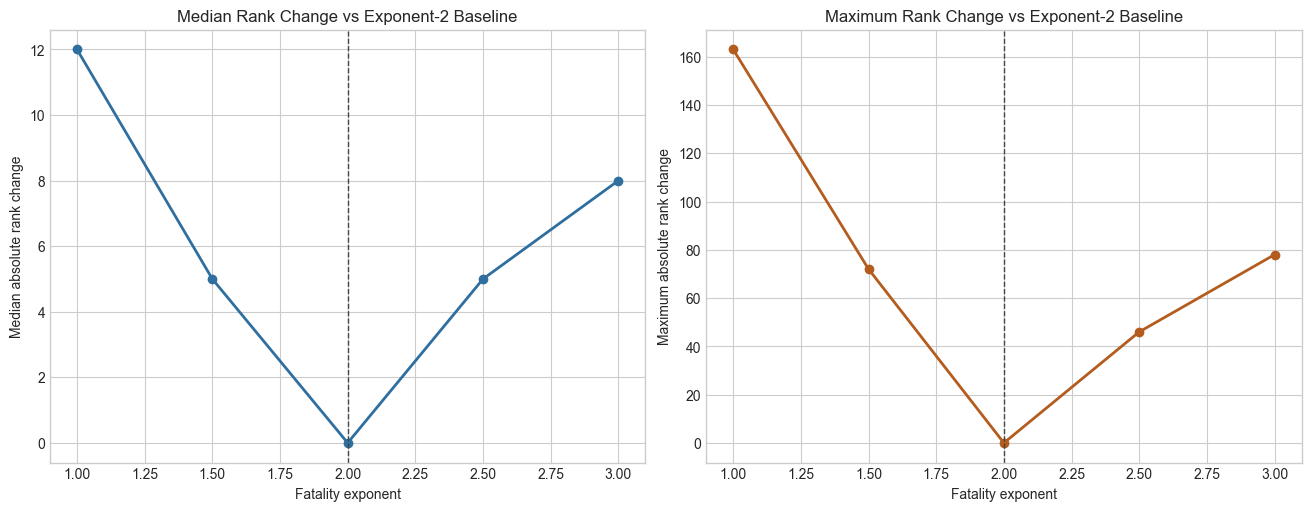

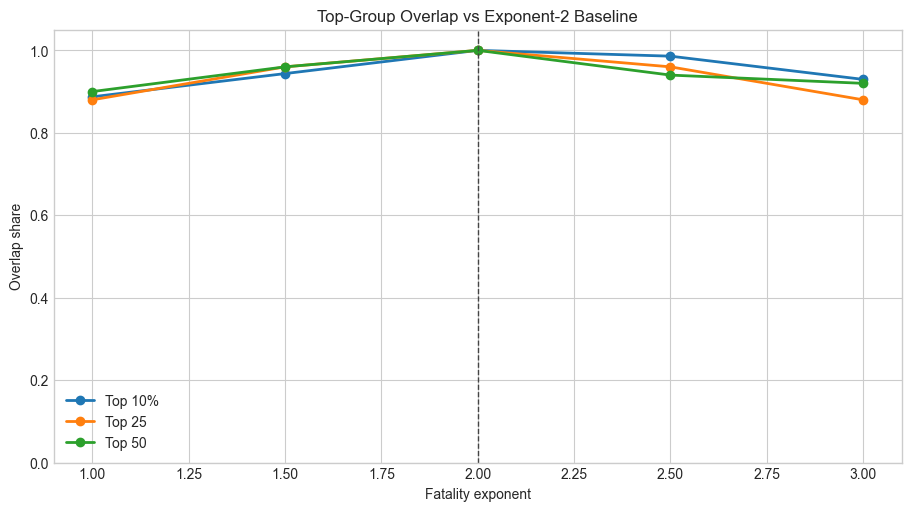

Saved outputs/figures/fatality_exponent_rank_stability.png
Saved outputs/figures/fatality_exponent_top_group_overlap.png


In [5]:
plt.style.use("seaborn-v0_8-whitegrid")

fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
axes[0].plot(summary_df["fatality_exponent"], summary_df["median_absolute_rank_change"], marker="o", color="#2f6f9f", linewidth=2)
axes[0].set_title("Median Rank Change vs Exponent-2 Baseline")
axes[0].set_xlabel("Fatality exponent")
axes[0].set_ylabel("Median absolute rank change")
axes[0].axvline(BASELINE_EXPONENT, color="#444444", linestyle="--", linewidth=1)

axes[1].plot(summary_df["fatality_exponent"], summary_df["maximum_rank_change"], marker="o", color="#b35c1e", linewidth=2)
axes[1].set_title("Maximum Rank Change vs Exponent-2 Baseline")
axes[1].set_xlabel("Fatality exponent")
axes[1].set_ylabel("Maximum absolute rank change")
axes[1].axvline(BASELINE_EXPONENT, color="#444444", linestyle="--", linewidth=1)

rank_stability_path = FIGURE_DIR / "fatality_exponent_rank_stability.png"
fig.savefig(rank_stability_path, dpi=200, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(9, 5), constrained_layout=True)
ax.plot(summary_df["fatality_exponent"], summary_df["top_10_percent_overlap_share"], marker="o", label="Top 10%", linewidth=2)
ax.plot(summary_df["fatality_exponent"], summary_df["top_25_overlap_share"], marker="o", label="Top 25", linewidth=2)
ax.plot(summary_df["fatality_exponent"], summary_df["top_50_overlap_share"], marker="o", label="Top 50", linewidth=2)
ax.set_title("Top-Group Overlap vs Exponent-2 Baseline")
ax.set_xlabel("Fatality exponent")
ax.set_ylabel("Overlap share")
ax.set_ylim(0, 1.05)
ax.axvline(BASELINE_EXPONENT, color="#444444", linestyle="--", linewidth=1)
ax.legend()

top_overlap_path = FIGURE_DIR / "fatality_exponent_top_group_overlap.png"
fig.savefig(top_overlap_path, dpi=200, bbox_inches="tight")
plt.show()

print(f"Saved {rank_stability_path.relative_to(PROJECT_ROOT)}")
print(f"Saved {top_overlap_path.relative_to(PROJECT_ROOT)}")

## Output Manifest

In [6]:
print("First sensitivity experiment complete: fatality exponent sensitivity.")
print("Baseline for comparison: correctly reconstructed exponent-2 DFSI, not published DFSI.")
print("Saved outputs:")
for path in [
    TABLE_DIR / "fatality_exponent_rankings.csv",
    TABLE_DIR / "fatality_exponent_summary.csv",
    TABLE_DIR / "fatality_exponent_top10_changes.csv",
    FIGURE_DIR / "fatality_exponent_rank_stability.png",
    FIGURE_DIR / "fatality_exponent_top_group_overlap.png",
]:
    print(f"- {path.relative_to(PROJECT_ROOT)} ({path.stat().st_size:,} bytes)")

First sensitivity experiment complete: fatality exponent sensitivity.
Baseline for comparison: correctly reconstructed exponent-2 DFSI, not published DFSI.
Saved outputs:
- outputs/tables/fatality_exponent_rankings.csv (857,471 bytes)
- outputs/tables/fatality_exponent_summary.csv (1,069 bytes)
- outputs/tables/fatality_exponent_top10_changes.csv (2,479 bytes)
- outputs/figures/fatality_exponent_rank_stability.png (150,344 bytes)
- outputs/figures/fatality_exponent_top_group_overlap.png (78,497 bytes)
